In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load dataset
df = sns.load_dataset("titanic")

# Inspect dataset
print("Dataset shape:", df.shape)

display(df.head())

df.info()

Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [4]:
display(df.describe().T)
print(df.columns.tolist()) 
display(df['survived'].value_counts())
display(df['survived'].value_counts(normalize=True)*100)
df.info()

,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


survived
0    549
1    342
Name: count, dtype: int64

survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [7]:
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [7]:
missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

display(missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Count,Missing Percentage
deck,688,77.216611
age,177,19.865320
embarked,2,0.224467
embark_town,2,0.224467
sex,0,0.000000
pclass,0,0.000000
survived,0,0.000000
fare,0,0.000000
parch,0,0.000000
sibsp,0,0.000000


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 107


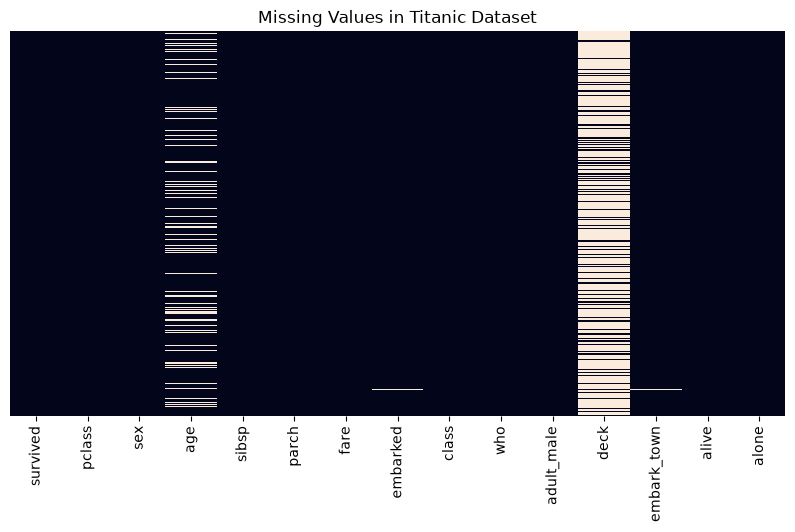

In [9]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in Titanic Dataset")
plt.show()

survived
0    549
1    342
Name: count, dtype: int64

Survival percentage:
survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


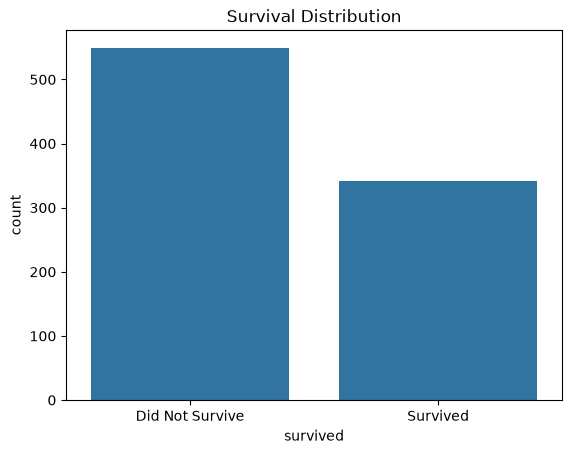

In [10]:
print(df["survived"].value_counts())

print("\nSurvival percentage:")
print(df["survived"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="survived")
plt.title("Survival Distribution")
plt.xticks([0, 1], ["Did Not Survive", "Survived"])
plt.show()

        count      mean
sex                    
female    314  0.742038
male      577  0.188908


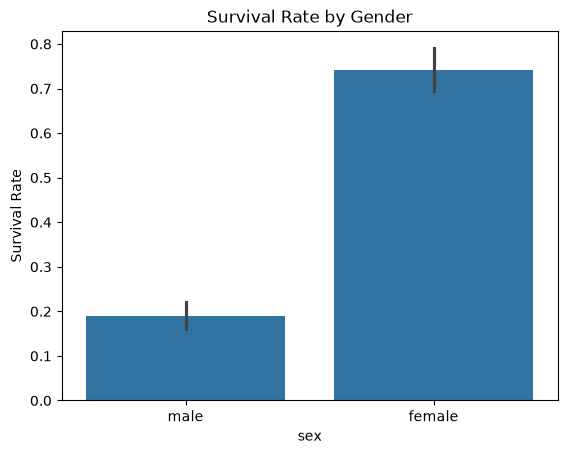

In [11]:
print(
    df.groupby("sex")["survived"]
    .agg(["count", "mean"])
)

sns.barplot(data=df, x="sex", y="survived")
plt.title("Survival Rate by Gender")
plt.ylabel("Survival Rate")
plt.show()

        count      mean
pclass                 
1         216  0.629630
2         184  0.472826
3         491  0.242363


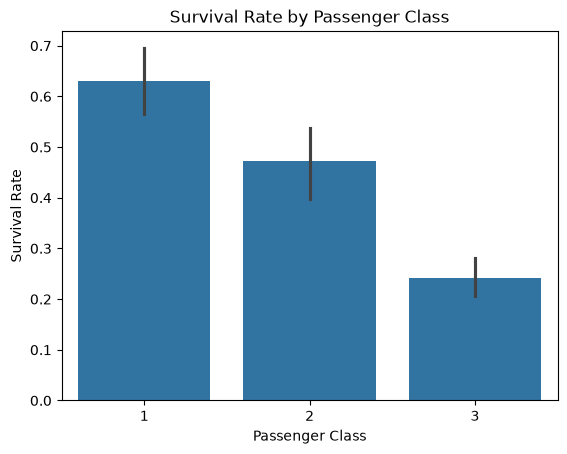

In [12]:
print(
    df.groupby("pclass")["survived"]
    .agg(["count", "mean"])
)

sns.barplot(data=df, x="pclass", y="survived")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

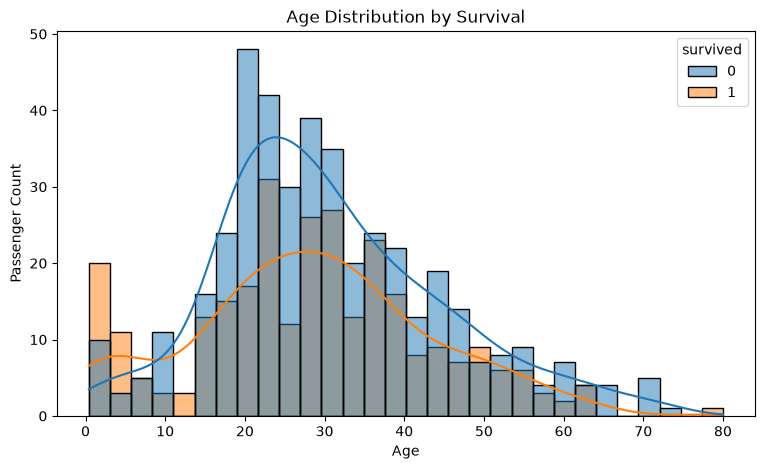

In [13]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="age",
    hue="survived",
    bins=30,
    kde=True,
    multiple="layer"
)

plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Passenger Count")
plt.show()

In [14]:
df.groupby("survived")["age"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
survived,,,
0,424,30.626179,28.0
1,290,28.343690,28.0


          count       mean  median
survived                          
0           549  22.117887    10.5
1           342  48.395408    26.0


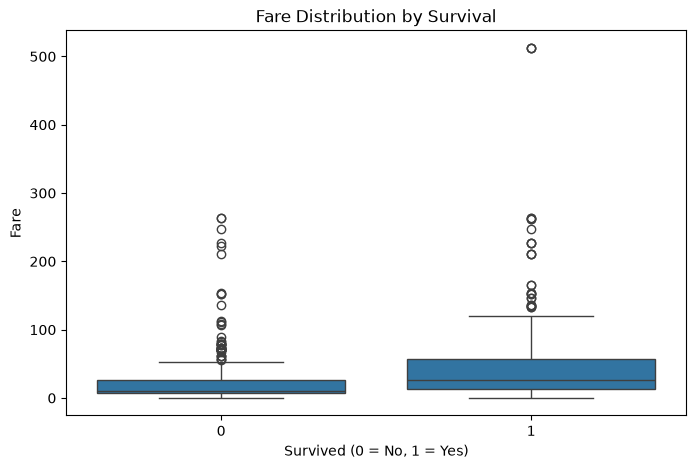

In [15]:
print(
    df.groupby("survived")["fare"]
    .agg(["count", "mean", "median"])
)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="survived", y="fare")

plt.title("Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")
plt.show()

          count      mean
embarked                 
C           168  0.553571
Q            77  0.389610
S           644  0.336957


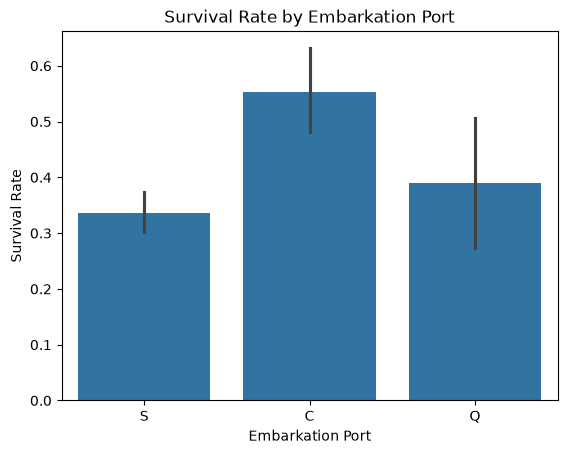

In [16]:
print(
    df.groupby("embarked")["survived"]
    .agg(["count", "mean"])
)

sns.barplot(data=df, x="embarked", y="survived")

plt.title("Survival Rate by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Rate")
plt.show()

In [17]:
# Select features
X = df[
    ["age", "sibsp", "parch", "fare",
     "sex", "embarked", "pclass"]
].copy()

# Target
y = df["survived"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nMissing values:")
print(X.isnull().sum())

Feature shape: (891, 7)
Target shape: (891,)

Feature columns:
['age', 'sibsp', 'parch', 'fare', 'sex', 'embarked', 'pclass']

Missing values:
age         177
sibsp         0
parch         0
fare          0
sex           0
embarked      2
pclass        0
dtype: int64


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (712, 7)
Testing features: (179, 7)

Training target distribution:
survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

Testing target distribution:
survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify columns
numeric_features = ["age", "sibsp", "parch", "fare"]
categorical_features = ["sex", "embarked", "pclass"]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using training statistics
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)
print("Remaining missing values in training:",
      pd.isna(X_train_processed).sum())
print("Remaining missing values in testing:",
      pd.isna(X_test_processed).sum())

Training shape: (712, 12)
Testing shape: (179, 12)
Remaining missing values in training: 0
Remaining missing values in testing: 0


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train
model.fit(X_train, y_train)

# Predict on unseen test data
y_pred = model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.8044692737430168

Confusion Matrix:

[[98 12]
 [23 46]]

Classification Report:

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [21]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8044692737430168
[[98 12]
 [23 46]]
